# 사출성형기 AI 데이터셋 변수 상관관계 분석

KAMP 가이드북의 2차 가공 데이터 정의를 기준으로 CN7과 RG3를 분리해 분석한다. `PassOrFail`은 0=양품, 1=불량이다. 변수 간 상관은 라벨·비라벨 전체 데이터를 사용하고, 불량 라벨과의 연관성은 라벨 데이터만 사용한다.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr, spearmanr, rankdata

warnings.filterwarnings('ignore', category=RuntimeWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / 'data'
REPORT_DIR = ROOT / 'reports'
TABLE_DIR = REPORT_DIR / 'tables'
FIGURE_DIR = REPORT_DIR / 'figures'
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
ROOT

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\hayeon\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


WindowsPath('C:/Users/hayeon/workspace/KAMP-IMM')

## 1. 데이터 로드와 품질 점검

`Unnamed: 0`은 원본 행 식별자이므로 분석 변수에서 제외한다. 결측, 중복, 상수열과 라벨 불균형을 먼저 확인한다.

In [2]:
products = ['cn7', 'rg3']
datasets = {}
quality_rows = []

for product in products:
    labeled = pd.read_csv(DATA_DIR / f'moldset_labeled_{product}.csv')
    unlabeled = pd.read_csv(DATA_DIR / f'moldset_unlabeled_{product}.csv')
    labeled = labeled.drop(columns=['Unnamed: 0'], errors='ignore')
    unlabeled = unlabeled.drop(columns=['Unnamed: 0'], errors='ignore')
    datasets[product] = {'labeled': labeled, 'unlabeled': unlabeled}
    for kind, frame in datasets[product].items():
        constants = frame.columns[frame.nunique(dropna=False) <= 1].tolist()
        quality_rows.append({
            'product': product.upper(), 'dataset': kind, 'rows': len(frame),
            'columns': frame.shape[1], 'missing_cells': int(frame.isna().sum().sum()),
            'duplicate_rows': int(frame.duplicated().sum()),
            'constant_columns': ', '.join(constants) if constants else ''
        })

quality = pd.DataFrame(quality_rows)
quality.to_csv(TABLE_DIR / 'data_quality_summary.csv', index=False, encoding='utf-8-sig')
quality

,product,dataset,rows,columns,missing_cells,duplicate_rows,constant_columns
0,CN7,labeled,1211,25,0,594,Clamp_Open_Position
1,CN7,unlabeled,35239,24,0,6468,
2,RG3,labeled,1182,25,0,566,Clamp_Open_Position
3,RG3,unlabeled,35941,24,0,6234,


In [3]:
label_rows = []
for product in products:
    y = datasets[product]['labeled']['PassOrFail']
    counts = y.value_counts().to_dict()
    label_rows.append({
        'product': product.upper(), 'good_0': int(counts.get(0, 0)),
        'defect_1': int(counts.get(1, 0)), 'defect_rate': float(y.mean())
    })
label_summary = pd.DataFrame(label_rows)
label_summary.to_csv(TABLE_DIR / 'label_distribution.csv', index=False, encoding='utf-8-sig')
label_summary.assign(defect_rate=label_summary['defect_rate'].map('{:.2%}'.format))

,product,good_0,defect_1,defect_rate
0,CN7,1194,17,1.40%
1,RG3,1157,25,2.12%


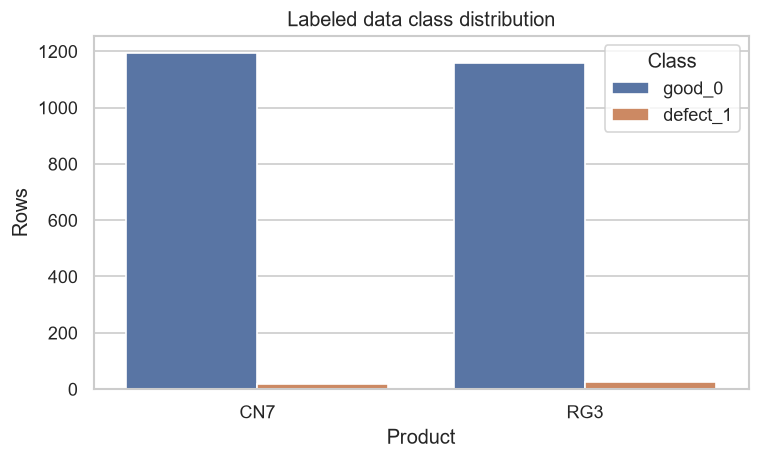

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 4))
plot_data = label_summary.melt(id_vars='product', value_vars=['good_0', 'defect_1'], var_name='class', value_name='count')
sns.barplot(data=plot_data, x='product', y='count', hue='class', ax=ax)
ax.set(title='Labeled data class distribution', xlabel='Product', ylabel='Rows')
ax.legend(title='Class')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'label_distribution.png', bbox_inches='tight')
plt.show()

## 2. 공정변수 간 상관관계

제품별로 라벨·비라벨 행을 합친 뒤 상수열을 제외한다. Pearson은 선형 관계, Spearman은 순위 기반 단조 관계를 나타낸다. 절댓값이 큰 변수쌍을 우선 확인한다.

In [5]:
def upper_triangle_pairs(corr, method):
    mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
    pairs = corr.where(mask).stack().rename('correlation').reset_index()
    pairs.columns = ['feature_1', 'feature_2', 'correlation']
    pairs['abs_correlation'] = pairs['correlation'].abs()
    pairs['method'] = method
    return pairs.sort_values('abs_correlation', ascending=False).reset_index(drop=True)

correlations = {}
pair_tables = {}
for product in products:
    labeled_x = datasets[product]['labeled'].drop(columns='PassOrFail')
    full_x = pd.concat([labeled_x, datasets[product]['unlabeled']], ignore_index=True)
    valid = full_x.columns[full_x.nunique(dropna=False) > 1]
    full_x = full_x[valid]
    pearson = full_x.corr(method='pearson')
    spearman = full_x.corr(method='spearman')
    correlations[product] = {'pearson': pearson, 'spearman': spearman}
    pairs = pd.concat([upper_triangle_pairs(pearson, 'pearson'), upper_triangle_pairs(spearman, 'spearman')])
    pairs.insert(0, 'product', product.upper())
    pair_tables[product] = pairs
    pairs.to_csv(TABLE_DIR / f'feature_pair_correlations_{product}.csv', index=False, encoding='utf-8-sig')

pd.concat(pair_tables.values(), ignore_index=True).groupby(['product', 'method']).head(10)

,product,feature_1,feature_2,correlation,abs_correlation,method
0,CN7,Mold_Temperature_3,Mold_Temperature_4,0.995039,0.995039,pearson
1,CN7,Plasticizing_Time,Average_Screw_RPM,0.983674,0.983674,pearson
2,CN7,Clamp_Close_Time,Cushion_Position,0.978177,0.978177,pearson
3,CN7,Max_Screw_RPM,Average_Screw_RPM,0.974951,0.974951,pearson
4,CN7,Cushion_Position,Average_Screw_RPM,0.973487,0.973487,pearson
5,CN7,Cushion_Position,Max_Back_Pressure,0.972615,0.972615,pearson
6,CN7,Plasticizing_Position,Max_Switch_Over_Pressure,0.971430,0.971430,pearson
7,CN7,Plasticizing_Position,Mold_Temperature_3,0.971143,0.971143,pearson
8,CN7,Cushion_Position,Barrel_Temperature_1,0.966680,0.966680,pearson
9,CN7,Plasticizing_Time,Cushion_Position,0.966353,0.966353,pearson


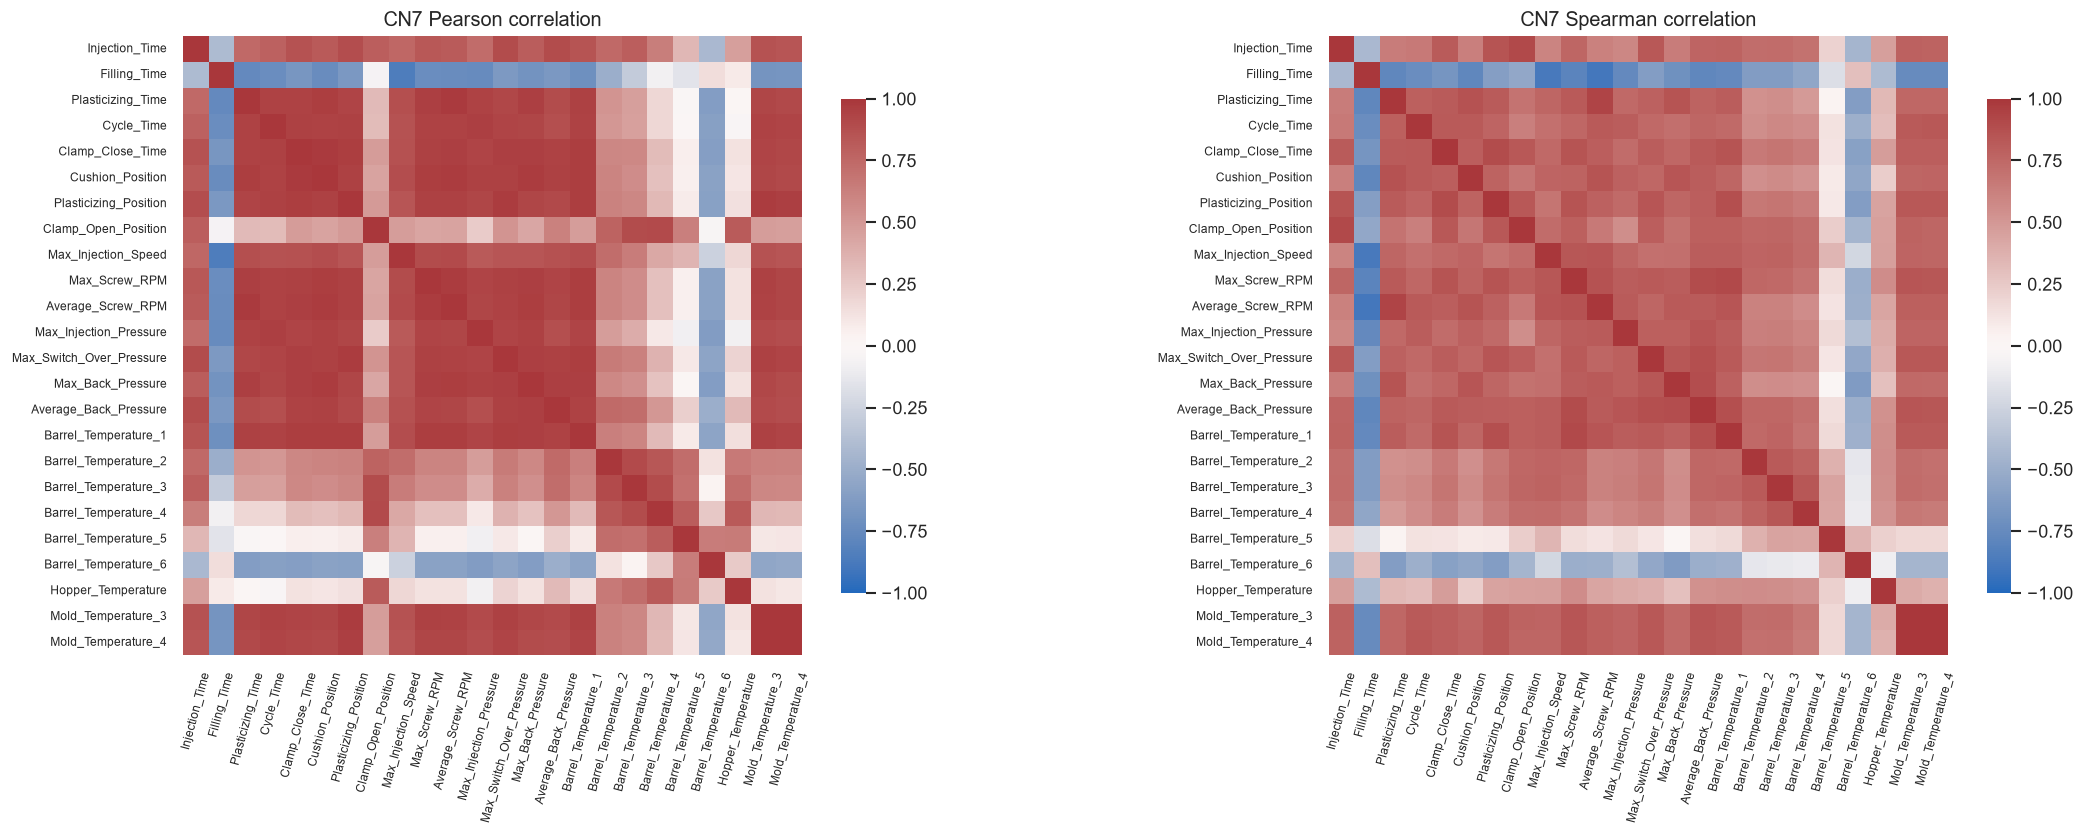

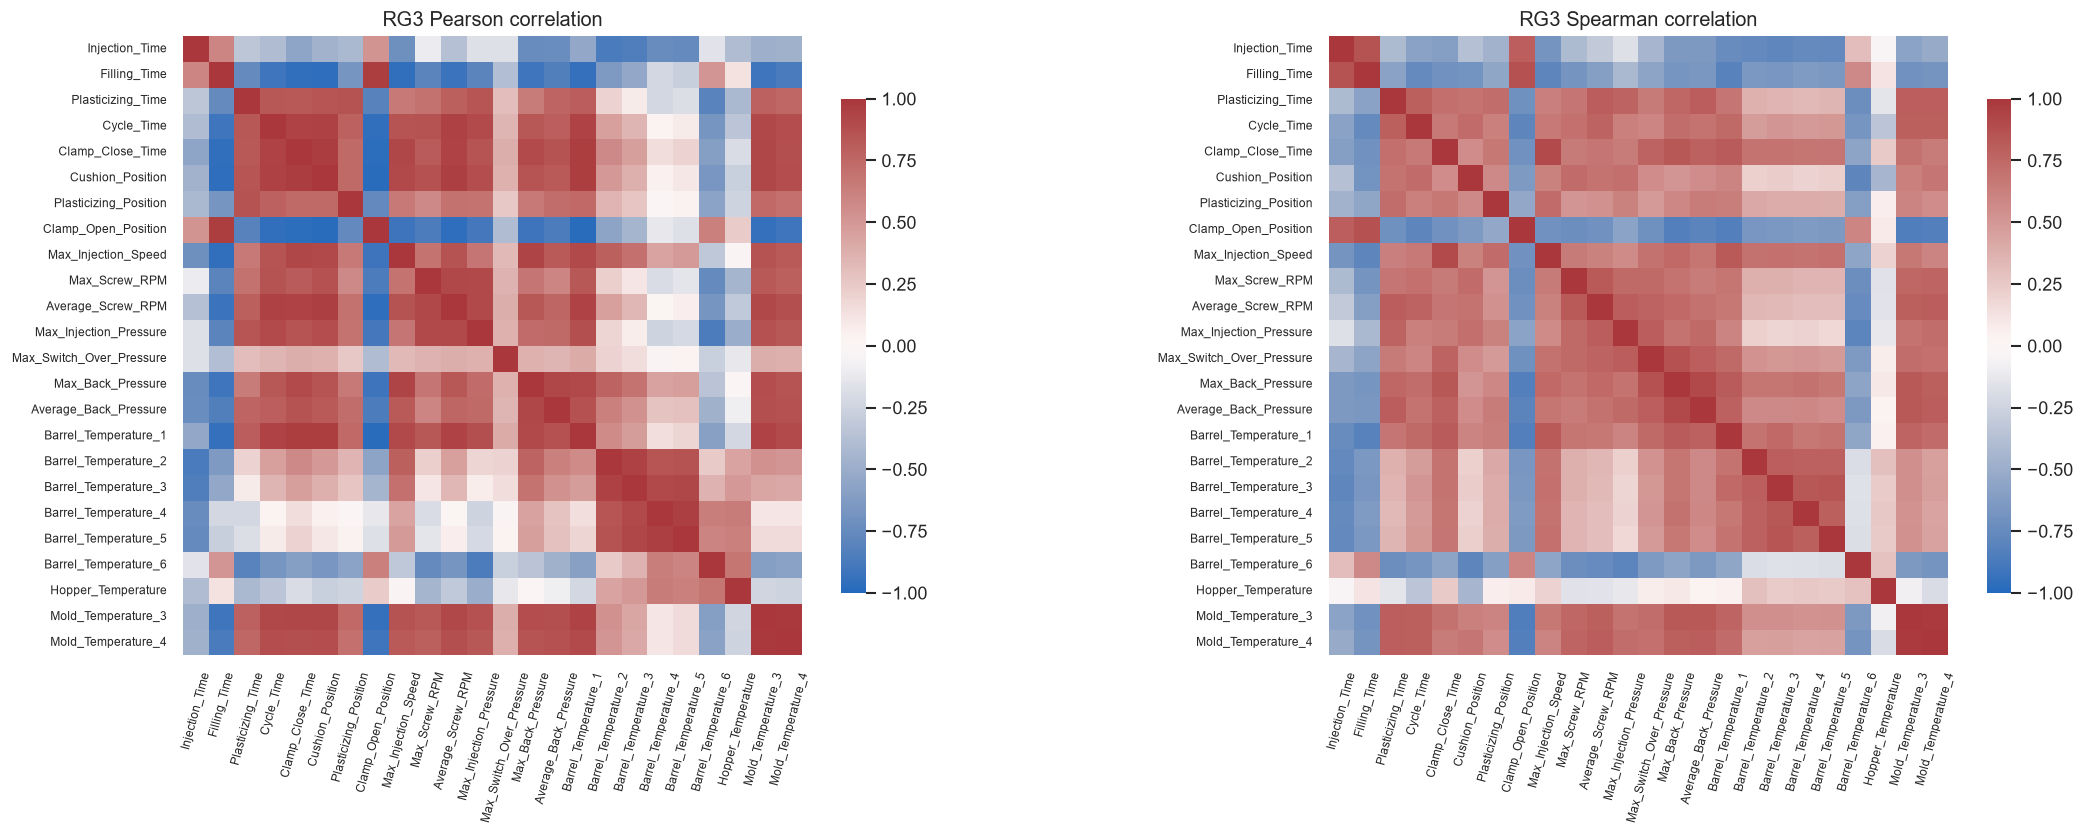

In [6]:
for product in products:
    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    for ax, method in zip(axes, ['pearson', 'spearman']):
        sns.heatmap(correlations[product][method], cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={'shrink': 0.75})
        ax.set_title(f'{product.upper()} {method.title()} correlation')
        ax.tick_params(axis='x', rotation=75, labelsize=7)
        ax.tick_params(axis='y', labelsize=7)
    fig.subplots_adjust(left=0.16, right=0.96, bottom=0.30, top=0.91, wspace=0.48)
    fig.savefig(FIGURE_DIR / f'correlation_heatmaps_{product}.png', bbox_inches='tight')
    plt.show()

## 3. 불량 라벨과 각 변수의 연관성

이진 라벨과 연속 변수의 선형 연관성은 point-biserial 상관으로 측정한다. Spearman 상관, 양품·불량 평균 차이의 pooled 표준편차 단위 효과크기, 단일 변수 AUC도 함께 제시한다. AUC는 방향을 뒤집어도 같은 분리력을 보도록 `max(AUC, 1-AUC)`를 사용한다. 희소 불량 라벨 때문에 결과는 탐색적으로 해석한다.

In [7]:
def bh_fdr(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    ranked = p[order] * len(p) / np.arange(1, len(p) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(ranked)
    out[order] = np.clip(ranked, 0, 1)
    return out

def label_associations(frame):
    y = frame['PassOrFail'].astype(int).to_numpy()
    n1, n0 = int(y.sum()), int((1 - y).sum())
    rows = []
    for feature in frame.columns.drop('PassOrFail'):
        x = frame[feature].astype(float).to_numpy()
        if np.unique(x).size <= 1:
            continue
        pb = pointbiserialr(y, x)
        sp = spearmanr(y, x)
        ranks = rankdata(x)
        auc = (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
        good, defect = x[y == 0], x[y == 1]
        pooled = np.sqrt(((n0 - 1) * good.var(ddof=1) + (n1 - 1) * defect.var(ddof=1)) / (n0 + n1 - 2))
        smd = (defect.mean() - good.mean()) / pooled if pooled > 0 else np.nan
        rows.append({
            'feature': feature, 'point_biserial': pb.statistic, 'p_value': pb.pvalue,
            'spearman': sp.statistic, 'spearman_p_value': sp.pvalue,
            'good_mean': good.mean(), 'defect_mean': defect.mean(),
            'standardized_mean_difference': smd, 'auc': auc,
            'auc_separation': max(auc, 1 - auc)
        })
    result = pd.DataFrame(rows)
    result['fdr_q_value'] = bh_fdr(result['p_value'])
    return result.sort_values(['auc_separation', 'point_biserial'], key=lambda s: s.abs() if s.name == 'point_biserial' else s, ascending=False)

label_tables = {}
for product in products:
    assoc = label_associations(datasets[product]['labeled'])
    assoc.insert(0, 'product', product.upper())
    label_tables[product] = assoc
    assoc.to_csv(TABLE_DIR / f'label_feature_associations_{product}.csv', index=False, encoding='utf-8-sig')

pd.concat(label_tables.values(), ignore_index=True).groupby('product').head(10)

,product,feature,point_biserial,p_value,spearman,spearman_p_value,good_mean,defect_mean,standardized_mean_difference,auc,auc_separation,fdr_q_value
0,CN7,Mold_Temperature_3,0.145175,3.902059e-07,0.161023,1.755298e-08,-0.017323,1.216657,1.246162,0.894226,0.894226,1.282105e-06
1,CN7,Mold_Temperature_4,0.163068,1.149569e-08,0.160183,2.085397e-08,-0.019458,1.366613,1.403715,0.892181,0.892181,6.610020e-08
2,CN7,Plasticizing_Position,0.178564,3.902755e-10,0.154026,7.178450e-08,-0.021307,1.496483,1.541307,0.869692,0.869692,4.488168e-09
3,CN7,Max_Back_Pressure,-0.176061,6.883398e-10,-0.143683,5.140461e-07,0.021008,-1.475507,-1.519006,0.148364,0.851636,5.277272e-09
4,CN7,Average_Back_Pressure,-0.159996,2.166836e-08,-0.141663,7.433091e-07,0.019091,-1.340872,-1.376573,0.155212,0.844788,9.967446e-08
5,CN7,Plasticizing_Time,-0.051182,7.500785e-02,-0.125974,1.098480e-05,0.006107,-0.428935,-0.435253,0.191226,0.808774,1.232272e-01
6,CN7,Clamp_Close_Time,0.143171,5.646503e-07,0.136593,1.834673e-06,-0.017084,1.199869,1.228605,0.791457,0.791457,1.442995e-06
7,CN7,Cushion_Position,-0.151526,1.169469e-07,-0.129721,5.934617e-06,0.018081,-1.269889,-1.301939,0.232708,0.767292,4.482964e-07
8,CN7,Max_Switch_Over_Pressure,0.101019,4.302558e-04,0.105634,2.309358e-04,-0.012054,0.846608,0.862364,0.757784,0.757784,9.895884e-04
9,CN7,Hopper_Temperature,-0.079547,5.610375e-03,-0.086216,2.675550e-03,0.009492,-0.666656,-0.677737,0.288624,0.711376,1.089322e-02


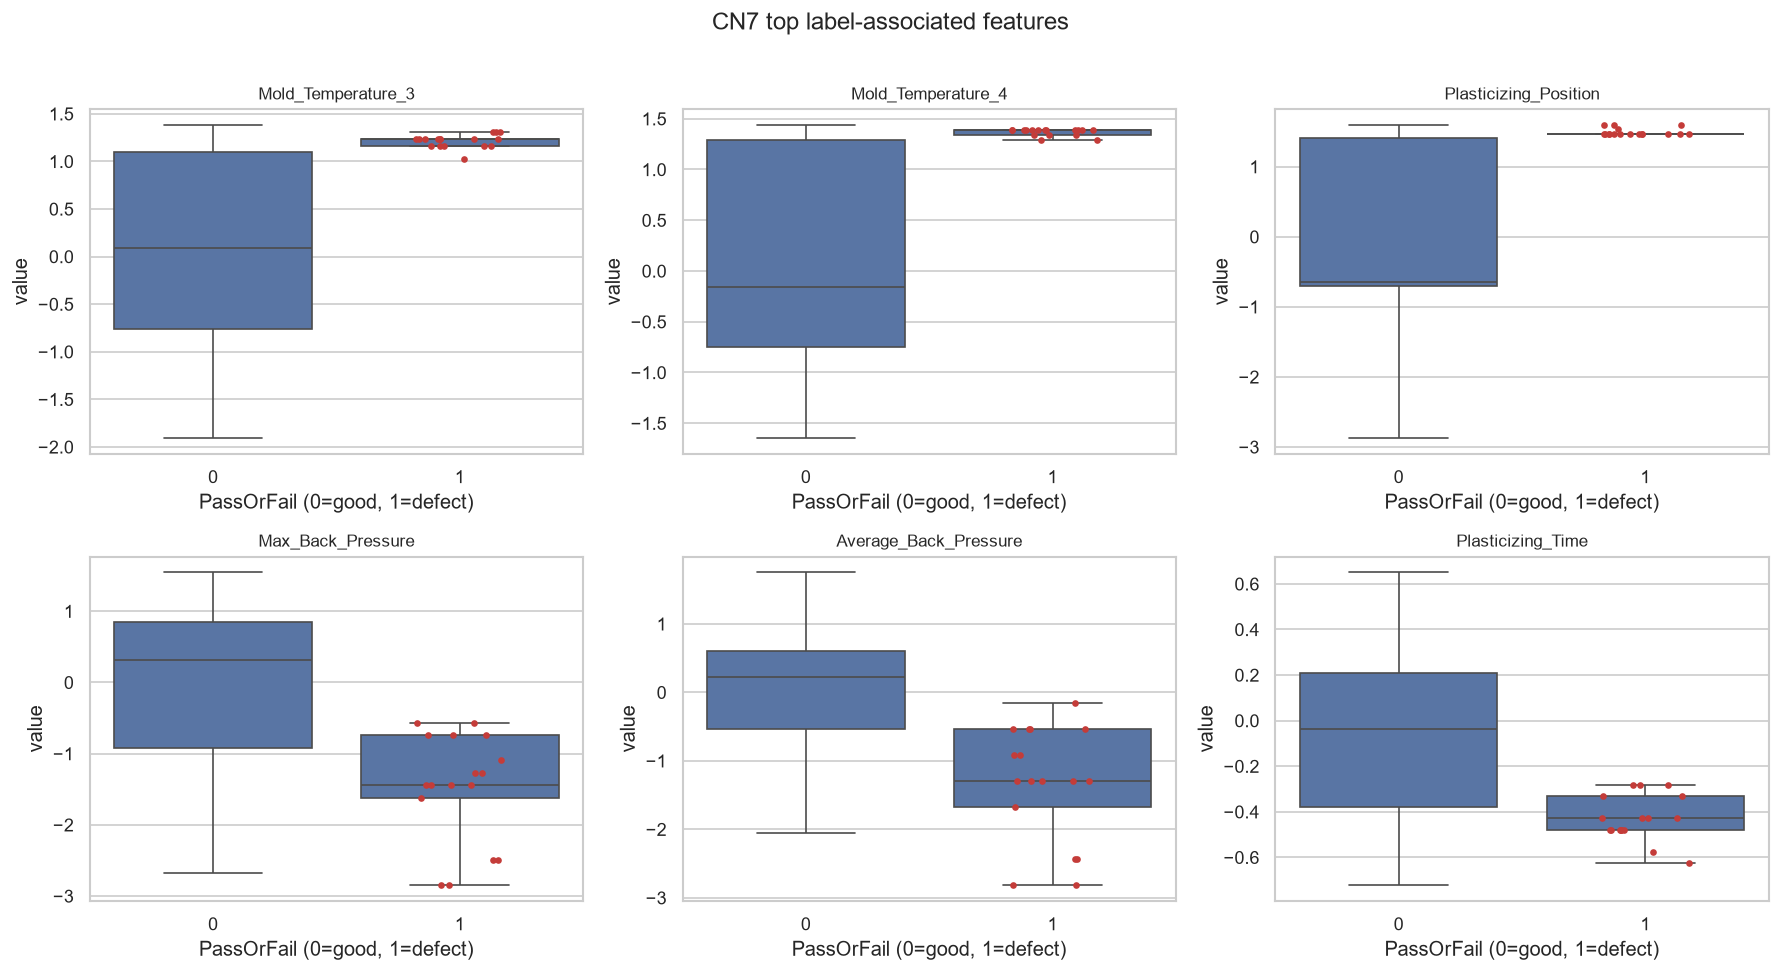

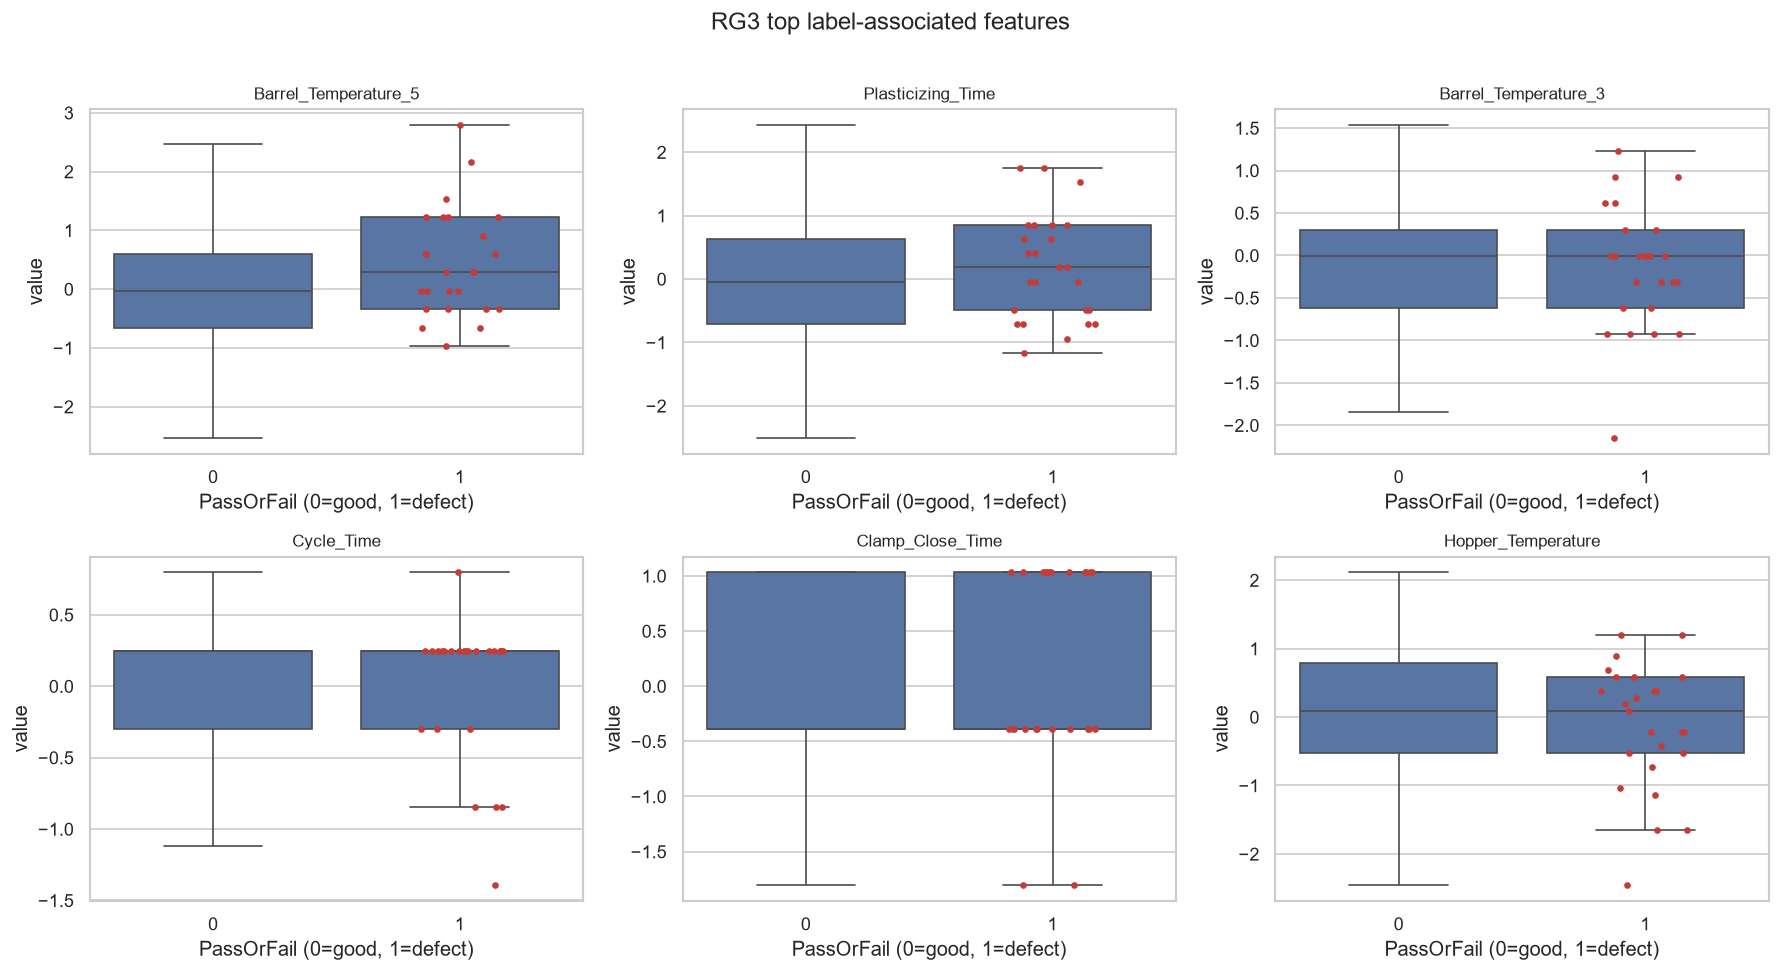

In [8]:
for product in products:
    top_features = label_tables[product].head(6)['feature'].tolist()
    long = datasets[product]['labeled'].melt(id_vars='PassOrFail', value_vars=top_features, var_name='feature', value_name='value')
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, feature in zip(axes.ravel(), top_features):
        sns.boxplot(data=long[long['feature'] == feature], x='PassOrFail', y='value', ax=ax, showfliers=False)
        sns.stripplot(data=long[(long['feature'] == feature) & (long['PassOrFail'] == 1)], x='PassOrFail', y='value', ax=ax, color='#c43c39', size=4, jitter=0.18)
        ax.set_title(feature, fontsize=10)
        ax.set_xlabel('PassOrFail (0=good, 1=defect)')
    fig.suptitle(f'{product.upper()} top label-associated features', y=1.01)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f'label_association_boxplots_{product}.png', bbox_inches='tight')
    plt.show()

## 4. 제품 간 상관 구조 비교

같은 변수쌍의 Pearson 상관이 CN7과 RG3에서 얼마나 다른지 비교한다. 차이가 큰 변수쌍은 제품별 모델을 분리해야 할 근거가 된다.

In [9]:
cn7_pairs = upper_triangle_pairs(correlations['cn7']['pearson'], 'pearson').set_index(['feature_1', 'feature_2'])['correlation']
rg3_pairs = upper_triangle_pairs(correlations['rg3']['pearson'], 'pearson').set_index(['feature_1', 'feature_2'])['correlation']
comparison = pd.concat([cn7_pairs.rename('cn7_correlation'), rg3_pairs.rename('rg3_correlation')], axis=1, join='inner').dropna()
comparison['difference_cn7_minus_rg3'] = comparison['cn7_correlation'] - comparison['rg3_correlation']
comparison['abs_difference'] = comparison['difference_cn7_minus_rg3'].abs()
comparison = comparison.sort_values('abs_difference', ascending=False).reset_index()
comparison.to_csv(TABLE_DIR / 'product_correlation_differences.csv', index=False, encoding='utf-8-sig')
comparison.head(15)

,feature_1,feature_2,cn7_correlation,rg3_correlation,difference_cn7_minus_rg3,abs_difference
0,Injection_Time,Barrel_Temperature_3,0.804179,-0.844348,1.648526,1.648526
1,Injection_Time,Average_Back_Pressure,0.898030,-0.728075,1.626104,1.626104
2,Injection_Time,Barrel_Temperature_2,0.746084,-0.868759,1.614843,1.614843
3,Injection_Time,Max_Back_Pressure,0.805736,-0.740202,1.545937,1.545937
4,Clamp_Open_Position,Average_Back_Pressure,0.624642,-0.862091,1.486734,1.486734
5,Injection_Time,Max_Injection_Speed,0.757795,-0.718646,1.476442,1.476442
6,Clamp_Open_Position,Barrel_Temperature_1,0.473734,-0.979613,1.453347,1.453347
7,Clamp_Close_Time,Clamp_Open_Position,0.479425,-0.972520,1.451945,1.451945
8,Clamp_Open_Position,Mold_Temperature_3,0.475638,-0.952715,1.428352,1.428352
9,Injection_Time,Clamp_Close_Time,0.859973,-0.561074,1.421047,1.421047


## 5. 자동 요약 보고서 생성

In [10]:
def pair_lines(product, method='pearson', n=8):
    table = pair_tables[product]
    table = table[table['method'] == method].head(n)
    return [f"- `{r.feature_1}` ↔ `{r.feature_2}`: {r.correlation:+.3f}" for r in table.itertuples()]

def label_lines(product, n=8):
    table = label_tables[product].head(n)
    return [f"- `{r.feature}`: point-biserial {r.point_biserial:+.3f}, Spearman {r.spearman:+.3f}, 방향보정 AUC {r.auc_separation:.3f}, FDR q={r.fdr_q_value:.3g}" for r in table.itertuples()]

report = [
    '# 사출성형기 데이터 변수 상관관계 요약', '',
    '## 데이터 점검', '',
    '- CN7 라벨 1,211건(불량 17건, 1.40%), 비라벨 35,239건',
    '- RG3 라벨 1,182건(불량 25건, 2.12%), 비라벨 35,941건',
    '- 네 CSV 모두 결측 셀과 완전 중복 행이 없다.',
    '- 라벨 데이터의 `Clamp_Open_Position`은 상수열이므로 라벨 연관성 계산에서 제외했다.',
    '- 불량 표본이 매우 적어 라벨 연관성 수치와 p-value는 탐색적 근거로만 사용해야 한다.', ''
]
for product in products:
    report += [f'## {product.upper()} 주요 변수쌍 (Pearson)', ''] + pair_lines(product) + ['', f'## {product.upper()} 불량 라벨 연관 변수', ''] + label_lines(product) + ['']
report += [
    '## 제품별 차이가 큰 변수쌍', '',
] + [f"- `{r.feature_1}` ↔ `{r.feature_2}`: CN7 {r.cn7_correlation:+.3f}, RG3 {r.rg3_correlation:+.3f}, 차이 {r.difference_cn7_minus_rg3:+.3f}" for r in comparison.head(10).itertuples()] + [
    '', '## 해석 주의사항', '',
    '- 상관관계는 인과관계를 뜻하지 않는다.',
    '- 공정변수는 동일 사이클 내에서 함께 제어되므로 높은 상관이 제어 로직이나 공정 단계 결합을 반영할 수 있다.',
    '- 다중공선성이 강한 변수는 예측 모델 투입 전 제거·집계·정규화 또는 규제 모델 사용을 검토한다.',
    '- 제품 간 상관 구조 차이가 커서 CN7과 RG3는 분리 모델 또는 제품 상호작용 항을 우선 검토한다.',
    '- 불량 원인 규명에는 시간 순서, 설비 설정값, 원재료·금형·작업 조건 같은 추가 맥락이 필요하다.'
]
report_path = REPORT_DIR / 'correlation_analysis_summary.md'
report_path.write_text('\n'.join(report), encoding='utf-8')
print('\n'.join(report))
print(f'\nSaved: {report_path}')

# 사출성형기 데이터 변수 상관관계 요약

## 데이터 점검

- CN7 라벨 1,211건(불량 17건, 1.40%), 비라벨 35,239건
- RG3 라벨 1,182건(불량 25건, 2.12%), 비라벨 35,941건
- 네 CSV 모두 결측 셀과 완전 중복 행이 없다.
- 라벨 데이터의 `Clamp_Open_Position`은 상수열이므로 라벨 연관성 계산에서 제외했다.
- 불량 표본이 매우 적어 라벨 연관성 수치와 p-value는 탐색적 근거로만 사용해야 한다.

## CN7 주요 변수쌍 (Pearson)

- `Mold_Temperature_3` ↔ `Mold_Temperature_4`: +0.995
- `Plasticizing_Time` ↔ `Average_Screw_RPM`: +0.984
- `Clamp_Close_Time` ↔ `Cushion_Position`: +0.978
- `Max_Screw_RPM` ↔ `Average_Screw_RPM`: +0.975
- `Cushion_Position` ↔ `Average_Screw_RPM`: +0.973
- `Cushion_Position` ↔ `Max_Back_Pressure`: +0.973
- `Plasticizing_Position` ↔ `Max_Switch_Over_Pressure`: +0.971
- `Plasticizing_Position` ↔ `Mold_Temperature_3`: +0.971

## CN7 불량 라벨 연관 변수

- `Mold_Temperature_3`: point-biserial +0.145, Spearman +0.161, 방향보정 AUC 0.894, FDR q=1.28e-06
- `Mold_Temperature_4`: point-biserial +0.163, Spearman +0.160, 방향보정 AUC 0.892, FDR q=6.61e-08
- `Plasticizing_Position`: point-biserial +0.179, Spearman +0.154, 방향보정 A